# Chapitre 3 - Cours 2 : sélection de variables, ridge et lasso

Ce notebook couvre les sections 3.3 et 3.4 du livre. Les moindres carrés ont deux défauts :

- **précision de prédiction** : ils sont sans biais mais souvent de grande variance ; en
  annulant ou en rétrécissant certains coefficients, on accepte un peu de biais pour
  réduire la variance (cf. cours 1, §5) ;
- **interprétation** : avec beaucoup de prédicteurs, on préfère un petit sous-ensemble aux
  effets les plus forts.

Deux familles de remèdes sont étudiées ici, toujours sur les données de la prostate :

1. la **sélection de sous-ensembles** : meilleur sous-ensemble, pas à pas ascendant et
   descendant, régression « stagewise » ;
2. les méthodes de **rétrécissement** (*shrinkage*) : régression **ridge** et **lasso**.

Nous reproduisons les figures 3.5, 3.8, 3.10, 3.11, 3.12 et les panneaux correspondants de
la figure 3.7 (courbes de validation croisée).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from sklearn.linear_model import Lasso, Ridge
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)


def label_ends(ax, x, values, labels, gap=0.035):
    """Écrit les noms des variables au bout des profils en évitant les chevauchements."""
    order = np.argsort(values)
    pos = np.array(values, float)[order]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + gap)
    for k, j in enumerate(order):
        ax.text(x, pos[k], labels[j], color=COLORS[j], fontsize=8, va="center")

Données de la prostate standardisées (comme au cours 1) : 67 observations
d'apprentissage, 30 de test, 8 prédicteurs.

In [2]:
Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()
N, p = Xtr.shape
fit_ls = cr.ols_fit(Xtr, ytr)


def test_error(b0, beta):
    """Erreur quadratique moyenne sur l'échantillon de test."""
    return np.mean((yte - b0 - Xte @ beta) ** 2)


print("moindres carrés : erreur de test = %.3f" % test_error(fit_ls["coef"][0], fit_ls["coef"][1:]))

moindres carrés : erreur de test = 0.521


## 1. Sélection du meilleur sous-ensemble

Pour chaque taille $k \in \{0, 1, \dots, p\}$, la **sélection du meilleur sous-ensemble**
(*best subset*) cherche le sous-ensemble de $k$ variables dont la régression par moindres
carrés a le plus petit RSS. Avec $p = 8$, il n'y a que $2^8 = 256$ sous-ensembles : on
peut tous les essayer. (Pour $p$ jusqu'à 30 ou 40, l'algorithme *leaps and bounds* évite
l'énumération complète ; au-delà, c'est impraticable.)

In [3]:
all_rss = cr.all_subsets_rss(Xtr, ytr)
subsets, best_rss = cr.best_subset(Xtr, ytr)
print("nombre de sous-ensembles :", len(all_rss))
pd.DataFrame({"meilleur sous-ensemble": [", ".join(names[j] for j in S) or "(constante)" for S in subsets],
              "RSS": best_rss}, index=pd.Index(range(p + 1), name="k"))

nombre de sous-ensembles : 256


,meilleur sous-ensemble,RSS
k,,
0,(constante),96.281
1,lcavol,44.529
2,"lcavol, lweight",37.092
3,"lcavol, lweight, svi",34.908
4,"lcavol, lweight, lbph, svi",32.815
5,"lcavol, lweight, lbph, svi, pgg45",32.069
6,"lcavol, lweight, lbph, svi, lcp, pgg45",30.540
7,"lcavol, lweight, age, lbph, svi, lcp, pgg45",29.437
8,"lcavol, lweight, age, lbph, svi, lcp, gleason,...",29.426


La figure 3.5 du livre montre le RSS de **tous** les sous-ensembles, rangés par taille ;
la frontière inférieure (en orange) est formée des meilleurs sous-ensembles.

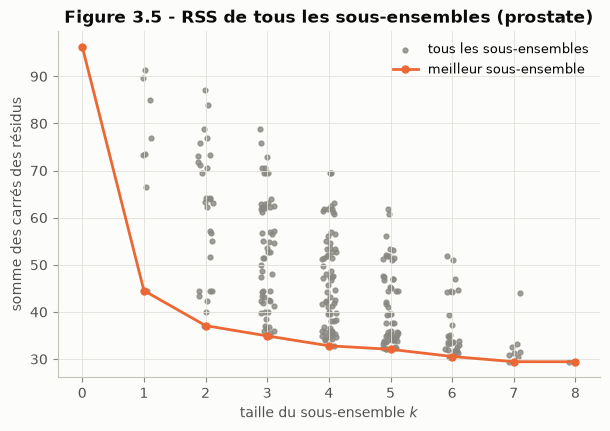

In [4]:
rng = np.random.RandomState(0)
ks = np.array([len(S) for S, _ in all_rss])
rs = np.array([r for _, r in all_rss])
fig, ax = plt.subplots()
ax.scatter(ks + rng.uniform(-0.12, 0.12, len(ks)), rs, s=12, color=GRAY, alpha=0.8,
           label="tous les sous-ensembles")
ax.plot(range(p + 1), best_rss, "o-", color=ORANGE, label="meilleur sous-ensemble")
ax.set_title("Figure 3.5 - RSS de tous les sous-ensembles (prostate)")
ax.set_xlabel("taille du sous-ensemble $k$"); ax.set_ylabel("somme des carrés des résidus")
ax.legend()
plt.show()

Ici les meilleurs sous-ensembles sont **emboîtés** (chacun contient le précédent), mais ce
n'est pas garanti en général. Surtout, la courbe des meilleurs RSS est **décroissante** :
plus de variables, meilleur ajustement sur l'apprentissage. Elle ne peut donc pas servir à
choisir $k$ ; il faut un critère qui estime l'**erreur de prédiction** sur de nouvelles
données.

## 2. Choisir la complexité : la validation croisée

La plupart des méthodes de ce chapitre produisent une **famille de modèles** indexée par
un paramètre de complexité ($k$, $\lambda$, $s$, $M$…). Pour choisir ce paramètre, on
utilise ici la **validation croisée à $K = 10$ plis** (détaillée au chapitre 7) :

1. on partage aléatoirement les $N$ observations d'apprentissage en $K$ parts égales ;
2. pour chaque part $\kappa$, on ajuste toute la famille sur les $K-1$ autres parts et
   l'on calcule l'erreur quadratique moyenne $e_\kappa$ sur la part $\kappa$ ;
3. l'erreur estimée est $\mathrm{CV} = \frac{1}{K}\sum_{\kappa} e_\kappa$, avec l'erreur
   standard $\mathrm{se} = \mathrm{sd}(e_1, \dots, e_K)/\sqrt{K}$.